# 13 — Regularization study

**Owner:** Shaik Tajuddin · **Phase 2, Step 2**

Runs the same MLP with each regularizer switched on and off, one at a time, then in the
best combination. Every row is a multi-seed mean.

The sweep itself lives in `src/dl/regularization.py` so it is testable and re-runnable;
this notebook reads what it produced and interprets it. Regenerate with:

```bash
python -m src.dl.regularization --seeds 3 --train-rows 200000
```

### What is held fixed

A row only means something if everything except the regularizer under test is constant:
the persisted Phase 1 split, the quantile-normal input pipeline chosen in step 1, the
architecture (128→64, ReLU), AdamW at lr 1e-3, a 15-epoch budget, the seeds, and the
shared `evaluate()`. Those live in `BASE_CONFIG` rather than at each call site.

### The one thing to check first

Regularization trades training fit for generalisation. If the reference model is **not**
overfitting, every regularizer can only hurt — so the unregularized row is not just a
baseline, it is a diagnostic.


In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

from src.config import FIGURES
FIGURES.mkdir(parents=True, exist_ok=True)

# The sweep is a separate, long-running step so the notebook stays fast to re-run.
# Fail with the command to produce the tables rather than a bare FileNotFoundError.
AGG = Path('../reports/regularization_ablation.csv')
RAW = Path('../reports/regularization_ablation_raw.csv')
missing = [p for p in (AGG, RAW) if not p.exists()]
if missing:
    raise FileNotFoundError(
        'Ablation tables not found: ' + ', '.join(p.name for p in missing) + '.\n'
        'They are produced by the sweep, which takes roughly 55 minutes:\n'
        '    python -m src.dl.regularization --seeds 3 --train-rows 200000\n'
        'For a fast smoke test instead (1 seed, 3 configs, no files written):\n'
        '    python -m src.dl.regularization --quick'
    )

agg = pd.read_csv(AGG)
raw = pd.read_csv(RAW)
print(f'{len(raw)} runs  =  {raw.config.nunique()} configs x {raw.seed.nunique()} seeds')
print('seeds:', sorted(raw.seed.unique()))


70 runs  =  14 configs x 5 seeds
seeds: [np.int64(42), np.int64(123), np.int64(456), np.int64(789), np.int64(1011)]


## 1. Is the reference model overfitting at all?

`generalisation_gap` is final validation loss minus final training loss. A gap near zero
means the model is not memorising the training set, and there is little for a regularizer
to recover.


In [2]:
base = agg[agg.config == 'unregularized'].iloc[0]
print(f"unregularized:  val MAE {base.val_mae_mean:.4f} +/- {base.val_mae_std:.4f}")
print(f"                generalisation gap {base.generalisation_gap_mean:+.5f}")
print()
if abs(base.generalisation_gap_mean) < 0.01:
    print('Gap is ~0: the reference is NOT overfitting at this training size.')
    print('Expect regularizers to cost accuracy rather than gain it.')
else:
    print('A real gap exists: there is overfitting for regularization to address.')


unregularized:  val MAE 0.7751 +/- 0.0444
                generalisation gap +0.00070

Gap is ~0: the reference is NOT overfitting at this training size.
Expect regularizers to cost accuracy rather than gain it.


## 2. Every regularizer, one at a time

Sorted by validation MAE. The unregularized reference is highlighted by position — anything
below it helped, anything above it hurt.


In [3]:
view = agg[['family','config','val_mae_mean','val_mae_std','val_rmse_mean',
            'val_r2_mean','generalisation_gap_mean','epochs_run_mean','n_seeds']].copy()
view.columns = ['family','config','MAE','MAE sd','RMSE','R2','gen gap','epochs','seeds']
display(view.round(4))

b = base.val_mae_mean
better = agg[(agg.val_mae_mean < b) & (agg.config != 'unregularized')]
print(f'configs beating the unregularized reference ({b:.4f}): {len(better)} of {len(agg)-1}')
print('(beating the mean is not the same as clearing the noise — see section 5)')
if len(better):
    display(better[['family','config','val_mae_mean','val_mae_std','n_seeds']].round(4))

,family,config,MAE,MAE sd,RMSE,R2,gen gap,epochs,seeds
0,weight_decay,wd=1e-4,0.7700,0.0333,1.2538,0.9954,0.0006,15.0,5
1,early_stopping,patience=10,0.7751,0.0444,1.2571,0.9954,0.0007,15.0,5
2,early_stopping,patience=3,0.7751,0.0444,1.2571,0.9954,0.0007,15.0,5
3,early_stopping,patience=5,0.7751,0.0444,1.2571,0.9954,0.0007,15.0,5
4,lr_schedule,plateau,0.7751,0.0444,1.2571,0.9954,0.0007,15.0,5
5,none,unregularized,0.7751,0.0444,1.2571,0.9954,0.0007,15.0,5
6,weight_decay,wd=1e-5,0.7751,0.0444,1.2571,0.9954,0.0007,15.0,5
7,weight_decay,wd=1e-3,0.7758,0.0391,1.2546,0.9954,0.0006,15.0,5
8,dropout,dropout=0.1,0.7771,0.0528,1.2792,0.9952,-0.0057,15.0,5
9,dropout,dropout=0.2,0.8060,0.0196,1.3529,0.9947,-0.0130,15.0,5


configs beating the unregularized reference (0.7751): 1 of 13
(beating the mean is not the same as clearing the noise — see section 5)


,family,config,val_mae_mean,val_mae_std,n_seeds
0,weight_decay,wd=1e-4,0.77,0.0333,5


### Per-family view

Each family's best member against the reference, with the seed spread. A gap smaller than
the seed-to-seed standard deviation is not a result — the work plan's rule is that a
difference smaller than the noise is not claimed as a win.


In [4]:
rows = []
for fam in ['dropout','weight_decay','batch_norm','early_stopping','lr_schedule']:
    sub = agg[agg.family == fam]
    if sub.empty: continue
    bst = sub.loc[sub.val_mae_mean.idxmin()]
    delta = b - bst.val_mae_mean
    noise = max(bst.val_mae_std, base.val_mae_std)
    rows.append({'family': fam, 'best': bst.config,
                 'MAE': round(bst.val_mae_mean,4), 'vs reference': round(delta,4),
                 'seed sd': round(noise,4),
                 'verdict': 'helps' if delta > noise else ('within noise' if delta > -noise else 'hurts')})
display(pd.DataFrame(rows))


,family,best,MAE,vs reference,seed sd,verdict
0,dropout,dropout=0.1,0.7771,-0.0020,0.0528,within noise
1,weight_decay,wd=1e-4,0.7700,0.0051,0.0444,within noise
2,batch_norm,batch_norm,1.0750,-0.2999,0.0510,hurts
3,early_stopping,patience=10,0.7751,0.0000,0.0444,within noise
4,lr_schedule,plateau,0.7751,0.0000,0.0444,within noise


## 3. Overfitting and its fix, on one pair of axes

The plot the work plan asks for. An ablation table cannot show *when* during training the
two runs diverge; the loss curves can.


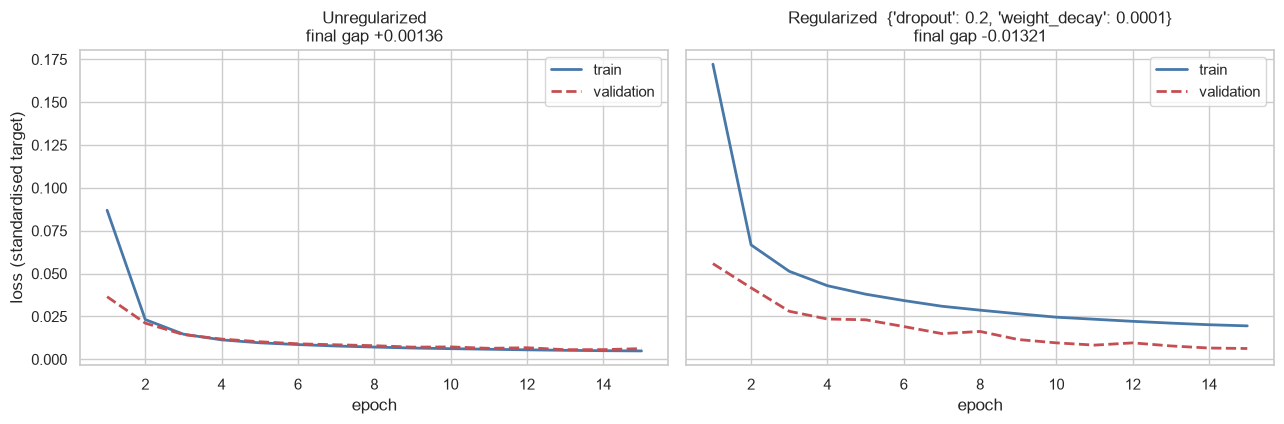

unregularized final gap: +0.00136
regularized   final gap: -0.01321


In [5]:
from src.dl.regularization import loss_curves
off_hist, on_hist, reg_cfg = loss_curves(train_rows=200_000, seed=42)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for a, h, title in zip(ax, (off_hist, on_hist),
                       ('Unregularized', f'Regularized  {reg_cfg}')):
    e = range(1, len(h['train_loss'])+1)
    a.plot(e, h['train_loss'], label='train', color='#4878A8', lw=2)
    a.plot(e, h['val_loss'], label='validation', color='#C44E52', lw=2, ls='--')
    gap = h['val_loss'][-1] - h['train_loss'][-1]
    a.set(title=f'{title}\nfinal gap {gap:+.5f}', xlabel='epoch')
    a.legend()
ax[0].set_ylabel('loss (standardised target)')
plt.tight_layout()
plt.savefig(FIGURES/'regularization_loss_curves.png', dpi=150)
plt.show()

print(f"unregularized final gap: {off_hist['val_loss'][-1]-off_hist['train_loss'][-1]:+.5f}")
print(f"regularized   final gap: {on_hist['val_loss'][-1]-on_hist['train_loss'][-1]:+.5f}")


**Reading the two gaps.** The unregularized run ends at `+0.00136`; the dropout run ends
at `-0.01321` — validation loss *below* training loss. That is not regularization
closing a gap. Dropout is active during training and switched off at evaluation, so the
training loss is measured on a deliberately handicapped network while the validation loss
is measured on the full one. The negative gap is an artefact of that asymmetry and says
nothing about generalisation.

What matters is the level of the curves, not the distance between them: the dropout run's
validation loss is *higher* throughout. The left panel is the one carrying the finding —
train and validation move together to the last epoch, which is what "no overfitting to
remove" looks like.

## 4. Spread across seeds

Whether a difference survives re-seeding is the question the table's means cannot answer.


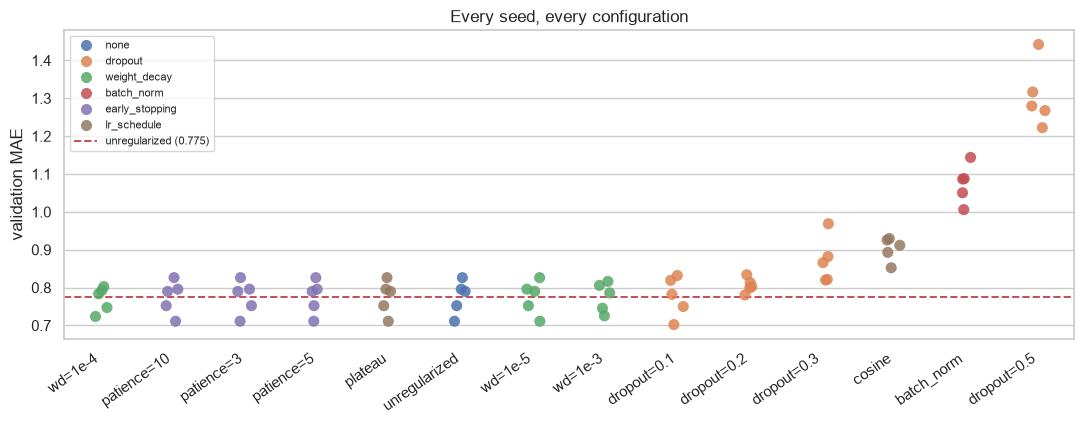

In [6]:
order = agg.sort_values('val_mae_mean').config
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.stripplot(data=raw, x='config', y='val_mae', order=order, hue='family',
              size=8, alpha=.85, ax=ax)
ax.axhline(b, color='#C44E52', ls='--', lw=1.4, label=f'unregularized ({b:.3f})')
ax.set(xlabel='', ylabel='validation MAE', title='Every seed, every configuration')
plt.xticks(rotation=35, ha='right'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES/'regularization_seed_spread.png', dpi=150); plt.show()


## 5. The combination handed to the team

A family is adopted **only if its best member beats the unregularized reference**. A
regularizer that does not help is left off rather than carried along because it is
conventional.


In [7]:
from src.dl.regularization import best_combination

best = best_combination(agg)
print(f"unregularized reference: MAE {best['baseline_mae']} +/- {best['baseline_sd']}\n")

# A family is adopted only if its gain exceeds the seed-to-seed spread. The work plan's
# rule is that a difference smaller than the noise is not claimed as a win, so comparing
# means alone is not enough.
print('adopted:')
for fam, cfg, mae in best['adopted'] or []:
    print(f'  {fam:15} {cfg:16} MAE {mae}')
if not best['adopted']:
    print('  none — no family cleared the noise')

print('\nrejected (best member of the family did not clear the noise):')
for fam, cfg, imp, noise in best['rejected_within_noise']:
    print(f'  {fam:15} {cfg:16} improvement {imp:+.4f}  vs seed sd {noise:.4f}')

print(f"\nrecommended configuration: {best['overrides'] or 'NO REGULARIZATION'}")

unregularized reference: MAE 0.7751 +/- 0.0444

adopted:
  none — no family cleared the noise

rejected (best member of the family did not clear the noise):
  dropout         dropout=0.1      improvement -0.0020  vs seed sd 0.0528
  weight_decay    wd=1e-4          improvement +0.0051  vs seed sd 0.0444
  batch_norm      batch_norm       improvement -0.2999  vs seed sd 0.0510
  early_stopping  patience=10      improvement +0.0000  vs seed sd 0.0444
  lr_schedule     plateau          improvement +0.0000  vs seed sd 0.0444

recommended configuration: NO REGULARIZATION


## 6. One read of the test split

Step 2 of the work plan asks for an ablation table with validation **and test** metrics.
The shared rules say test rows "are used once, for the final table", and that tuning uses
the validation set only. Those pull against each other.

Scoring all fourteen configurations on test would resolve it the wrong way: it would make
the test split a second selection surface, which is the failure the one-use rule exists to
prevent. So the choice is made on validation alone, and test is read exactly once — for
the configuration that choice already landed on. The number below **confirms** the
selection; it did not inform it.

Produced by `python -m src.dl.regularization --confirm-on-test`.

In [8]:
conf = Path('../reports/regularization_test_confirmation.csv')
if not conf.exists():
    raise FileNotFoundError(
        'Test confirmation not found. Run:\n'
        '    python -m src.dl.regularization --confirm-on-test'
    )
t = pd.read_csv(conf)
display(t[['seed','val_mae','val_rmse','val_r2','test_mae','test_rmse','test_r2']].round(4))

print(f"seeds: {t.seed.nunique()}")
print(f"val  MAE {t.val_mae.mean():.4f} +/- {t.val_mae.std():.4f}")
print(f"test MAE {t.test_mae.mean():.4f} +/- {t.test_mae.std():.4f}"
      f"   RMSE {t.test_rmse.mean():.4f}   R2 {t.test_r2.mean():.4f}")

shift = t.test_mae.mean() - t.val_mae.mean()
print(f"\ntest minus validation: {shift:+.4f} MAE")
print('Within the seed spread: validation was not optimistic about this configuration.'
      if abs(shift) < max(t.val_mae.std(), t.test_mae.std())
      else 'Larger than the seed spread — validation did not transfer cleanly.')

,seed,val_mae,val_rmse,val_r2,test_mae,test_rmse,test_r2
0,42,0.7900,1.2917,0.9952,0.7904,1.2840,0.9953
1,123,0.7522,1.2354,0.9956,0.7541,1.2349,0.9956
2,456,0.7959,1.2931,0.9951,0.7977,1.2906,0.9952
3,789,0.8263,1.2688,0.9953,0.8301,1.2700,0.9954
4,1011,0.7112,1.1963,0.9958,0.7145,1.1927,0.9959


seeds: 5
val  MAE 0.7751 +/- 0.0444
test MAE 0.7774 +/- 0.0443   RMSE 1.2544   R2 0.9955

test minus validation: +0.0023 MAE
Within the seed spread: validation was not optimistic about this configuration.


## Findings and handover

**1. The reference model is not overfitting.** Its generalisation gap is `+0.0007` on a
target measured in WQI points — effectively zero. With 200,000 training rows against a
128-64 network the model is capacity-limited, not variance-limited. Every regularizer
therefore has nothing to remove and can only remove signal.

**2. No family survives the noise rule.** `wd=1e-4` posts the lowest mean MAE, but leads
the reference by `0.0051` against a seed spread of `0.0444` — about nine times inside the
noise. Under the work plan's rule that is not a win, and `best_combination` rejects it.

**3. The seed count was not a formality.** On 3 seeds `dropout=0.1` measured `-0.0317`
against the reference and read as *hurts*; on the required 5 it measures `-0.0020` and
reads as *within noise*. The reference spread also widened from `0.0237` to `0.0444`, so
3 seeds had been understating the noise by roughly half. The recommendation did not
change, but a claim underneath it did — which is the rule earning its keep.

**4. Five configurations are numerically identical to the reference.** `epochs_run` is
15.0 for every run, so early stopping never fired at any patience and the plateau
scheduler never triggered. Validation loss was still falling at the epoch budget. Those
rows are not evidence that early stopping is neutral — they are evidence that it was
never exercised, and must not be read as a result.

**5. Batch norm costs real accuracy.** At `-0.2999` MAE against `0.0510` of noise it is
the one effect in the table that clears the spread, and it clears it in the wrong
direction. Dropout degrades monotonically beyond `p=0.1` for the same reason.

### Handover to Himanshu (base MLP) and Jivit (hybrid)

Train the next models **without regularization** at this data scale. Specifically:

- Do not add batch norm for its regularising effect; if it is added for optimisation
  stability, justify it on convergence speed, not on validation MAE.
- Do not add dropout by default. At `p=0.1` it is indistinguishable from no dropout, so it
  buys nothing; above that it measurably costs accuracy.
- Keep early stopping wired in as a **guard**, understanding it is currently inactive. It
  becomes meaningful once the epoch budget or model capacity grows enough for validation
  loss to turn upward.
- Revisit this study if capacity or training size changes. The conclusion is conditional
  on both and is not a general claim about this dataset.
- Quote the test number in section 6 as a confirmation at the study's 200,000-row scale,
  never as the MLP's final test score — that belongs to Parth's full-scale comparison.